# Chapters 1 & 2 — review

What the acquisition and aggregation stages do **now**, what was wrong before, and what is
still open. Every number here is read from the pipeline's own outputs, not retyped.

Narrative and decisions: `docs/ch1_ch2_summary.md`.
Threshold evidence: `docs/ch2_grouping_diagnostics.md` ·
Before/after per change: `docs/ch2_cleanup_changes.md` ·
The `99` decision: `docs/memo_unknown_parental_age.md`.

Regenerate the inputs with `pixi run Rscript notebooks/export_ch1_ch2.R`.
This notebook is **read-only** — it never writes into the pipeline.

In [1]:
import pandas as pd, matplotlib.pyplot as plt, matplotlib as mpl
from pathlib import Path

EXP = Path("..") / "input-data-processed" / "py-export"
if not EXP.exists():
    EXP = Path("input-data-processed") / "py-export"

# Validated categorical palette (dataviz reference instance, light mode).
# Assigned in fixed order and never cycled.
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
INK, INK2, GRID = "#0b0b0b", "#52514e", "#dcdcd8"

mpl.rcParams.update({
    "figure.dpi": 120, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.titlesize": 11, "axes.titleweight": "600", "axes.labelsize": 9,
    "xtick.color": INK2, "ytick.color": INK2, "xtick.labelsize": 8, "ytick.labelsize": 8,
    "axes.spines.top": False, "axes.spines.right": False,
    "grid.color": GRID, "grid.linewidth": 0.6, "legend.frameon": False, "legend.fontsize": 8,
    "font.size": 9, "lines.linewidth": 2,
})

def load(name):
    return pd.read_parquet(EXP / f"{name}.parquet")

panels   = load("ch1_panels")
events   = load("ch1_events_by_year")
muni     = load("ch2_municipalities")
units    = load("ch2_units")
adjacency= load("ch2_adjacency")
sweep    = load("ch2_threshold_sweep")
try:
    unknown = load("ch1_unknown_parent_age")
except Exception:
    unknown = None

print(f"panels {len(panels)} | municipalities {len(muni)} | units {len(units)}")

panels 75 | municipalities 2457 | units 777


---
## Chapter 1 — acquisition

### 1.1 Coverage

Every per-year panel is verified against a manifest of its **row count and event total**, not
its filename. `ch1_020_verify_inputs.R` re-checks all of this in seconds — run that instead of
re-running acquisition.

In [2]:
cov = (panels.groupby("prefix")
       .agg(panels=("year","size"), first=("year","min"), last=("year","max"),
            rows=("rows","sum"), events=("total","sum")))
cov["events"] = cov["events"].map("{:,.0f}".format)
cov["rows"] = cov["rows"].map("{:,.0f}".format)
cov

,panels,first,last,rows,events
prefix,,,,,
fert,40,1985,2024,"9,013,050","181,764,801"
mort,35,1990,2024,"1,459,563","11,696,980"


findfont: Failed to find font weight 600, now using 700.


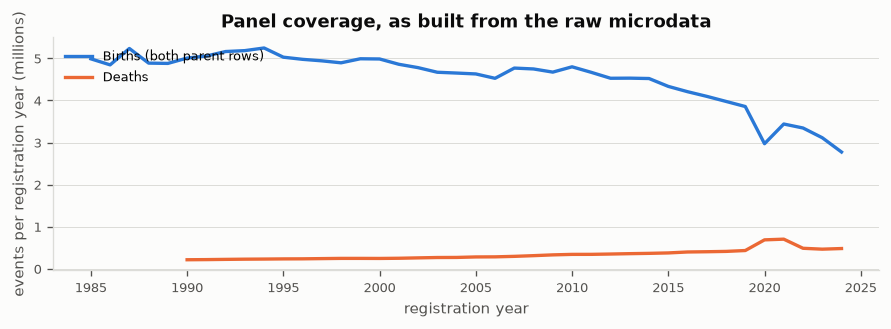

In [3]:
fig, ax = plt.subplots(figsize=(7.5, 2.8))
for name, colour, label in [("fert", BLUE, "Births (both parent rows)"),
                            ("mort", ORANGE, "Deaths")]:
    d = panels[panels.prefix == name].sort_values("year")
    ax.plot(d.year, d.total / 1e6, color=colour, label=label)
ax.set_ylabel("events per registration year (millions)")
ax.set_xlabel("registration year")
ax.set_title("Panel coverage, as built from the raw microdata")
ax.grid(axis="y"); ax.set_axisbelow(True); ax.legend(loc="upper left")
plt.tight_layout(); plt.show()

Births are roughly double the true count: `sex` is the **parent's** sex, so every birth appears
on the mother's row and the father's. Mother rows are the meaningful figure.

### 1.2 Cost of re-running

Measured on this machine. The point of the caching work is that none of the left column needs
to happen again.

| stage | before | after |
|---|---|---|
| `ch1_011` extraction | **13 GB re-extracted every run** | 2.7 s, 51/51 verified |
| `ch1_012` panels | ~10.7 min | 7.6 s |
| `ch2_040` | ~7 min | 58 s |

Both skips are payload checks: deleting an extracted file or silently truncating a panel is
detected and repaired. A check that only ever passes is worthless, so both were fault-injection
tested.

### 1.3 Registration delay is real and large

This is the structure Chapters 3–4 exist to model — and the reason `year` (occurrence) and
`year_reg` (registration) must never be conflated.

In [4]:
d = events[(events.year >= 1990) & (events.delay >= 0)].copy()
d["bucket"] = pd.cut(d.delay, [-1,0,1,2,5,10,200],
                     labels=["same year","1","2","3-5","6-10","11+"])
tot = d.groupby(["source","bucket"], observed=True).events.sum().unstack("source")
(100 * tot / tot.sum()).round(2).rename_axis("delay (years)")

source,births,deaths
delay (years),,
same year,10.00,98.06
1,-6.26,1.64
2,3.66,0.09
3-5,5.12,0.10
6-10,1.54,0.06
11+,0.43,0.04


Note these are shares of **events**. Until this round the delay figures summed panel *rows*, so
a cell holding 1 death counted the same as one holding 5,000 — which inflated long delays and
is the mechanical reason the thesis contradicts itself between its Figure 4 and Figure 5.

### 1.4 Open question: unknown parental age

INEGI codes unspecified parental age as `99`. The preprocessing keeps mothers 15–64 and fathers
15–84, so those records fall outside the range and are **silently discarded** — never a
decision, just a side effect of a biological-plausibility filter.

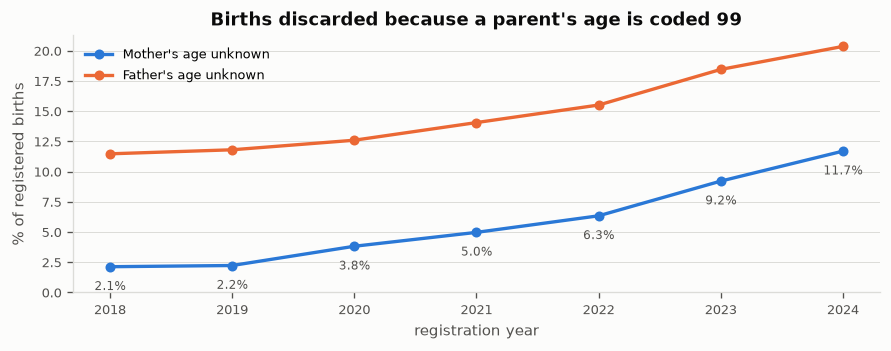

,year_reg,records,unknown_mother,pct_unknown_mother,pct_unknown_father
0,2018,2162535,45851,2.12,11.46
1,2019,2092214,46438,2.22,11.80
2,2020,1629211,62126,3.81,12.59
3,2021,1912178,94908,4.96,14.05
4,2022,1891388,119786,6.33,15.50
5,2023,1820888,167632,9.21,18.45
6,2024,1672227,195421,11.69,20.35


In [5]:
if unknown is None:
    print("raw births CSVs not present - skipping")
else:
    fig, ax = plt.subplots(figsize=(7.5, 3.0))
    ax.plot(unknown.year_reg, unknown.pct_unknown_mother, color=BLUE, marker="o",
            markersize=5, label="Mother's age unknown")
    ax.plot(unknown.year_reg, unknown.pct_unknown_father, color=ORANGE, marker="o",
            markersize=5, label="Father's age unknown")
    for _, r in unknown.iterrows():
        ax.annotate(f"{r.pct_unknown_mother:.1f}%", (r.year_reg, r.pct_unknown_mother),
                    textcoords="offset points", xytext=(0,-14), ha="center",
                    fontsize=7, color=INK2)
    ax.set_ylabel("% of registered births"); ax.set_xlabel("registration year")
    ax.set_ylim(bottom=0)
    ax.set_title("Births discarded because a parent's age is coded 99")
    ax.grid(axis="y"); ax.set_axisbelow(True); ax.legend(loc="upper left")
    plt.tight_layout(); plt.show()
    display(unknown[["year_reg","records","unknown_mother","pct_unknown_mother",
                     "pct_unknown_father"]].round(2))

**Why it matters.** The discarded births leave the numerator; the CONAPO population denominator
is unaffected. So fertility rates are biased down by roughly the unknown share — and because
that share is *rising*, part of the measured recent fertility decline is a coding artefact, in
exactly the window Chapter 4 attributes to registration delay.

By 2024 more than one birth in nine is discarded. It is also **not missing-at-random**: among records with unknown mother's age, education is
specified in 58.4% (vs 92.9%) and activity in 67.6% (vs 94.4%).

Fathers are a different problem — 70.3% of father-`99` records carry no father information at
all (mother-only registration), so most are *absent* fathers, not unknown-aged ones.
Redistributing them would invent ~206,000 fathers in 2022 alone.

The 2019 point was missing from an earlier version of this chart: that year ships its columns
as `EDAD_MADN` where the others use `edad_madn`, and a case-sensitive match skipped it — the
same case-sensitivity hazard CLAUDE.md flags for filenames.

**Nothing has been implemented.** Options are in `docs/memo_unknown_parental_age.md`.

---
## Chapter 2 — aggregation

### 2.1 The contiguity graph was broken

GADM's polygons overlap by numerical slivers rather than sharing exact boundaries, so every
*boundary*-based construction fails identically. A planar contiguity graph averages 5–6
neighbours.

In [6]:
a = adjacency.copy()
a["edges"] = a.edges.map("{:,.0f}".format)
a["mean_neighbours"] = a.mean_neighbours.round(2)
a

,method,edges,mean_neighbours,polygons_with_none
0,st_touches (previous),"2,039",1.66,658
1,"st_intersects + 10 m snap, EPSG:6372 (current)","7,173",5.84,0


655 of 2,457 municipalities had **no neighbour at all** and fell through to a nearest-centroid
fallback — welded to whatever polygon was closest by centroid, adjacent or not. The current
graph has zero orphans and one connected component, and `build_contiguity()` asserts on those
numbers.

### 2.2 The merge loop never stopped at the threshold

Unit populations were frozen at the start of each round, so a unit kept absorbing neighbours
long after clearing 50,000.

| at a 50,000 threshold | before | after |
|---|---|---|
| units | 552 | **777** |
| median unit population | 136,566 | 90,110 |
| largest unit | **153 municipalities** | 55 |
| centroid fallbacks | many | 0 |

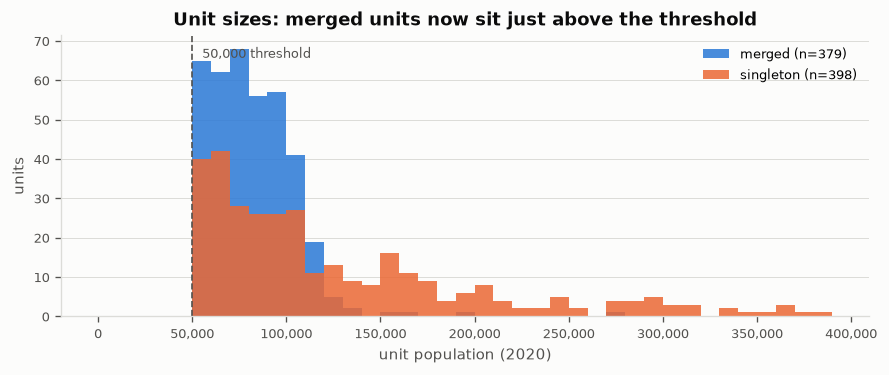

           count      25%       50%       75%        max
kind                                                    
merged     379.0  65663.0   79235.0   95388.0   279810.0
singleton  398.0  77898.0  118410.0  251146.0  1961388.0


In [7]:
fig, ax = plt.subplots(figsize=(7.5, 3.2))
bins = range(0, 400_000, 10_000)
for kind, colour in [("merged", BLUE), ("singleton", ORANGE)]:
    ax.hist(units[units.kind == kind].total_pop, bins=bins, color=colour, alpha=0.85,
            label=f"{kind} (n={(units.kind==kind).sum()})")
ax.axvline(50_000, color=INK2, linestyle="--", linewidth=1)
ax.annotate("50,000 threshold", (50_000, ax.get_ylim()[1]*0.92),
            textcoords="offset points", xytext=(6,0), fontsize=8, color=INK2)
ax.xaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.set_xlabel("unit population (2020)"); ax.set_ylabel("units")
ax.set_title("Unit sizes: merged units now sit just above the threshold")
ax.grid(axis="y"); ax.set_axisbelow(True); ax.legend()
plt.tight_layout(); plt.show()

print(units.groupby("kind").total_pop.describe()[["count","25%","50%","75%","max"]]
          .round(0).to_string())

Merged units cluster just above 50,000, which is what the stopping rule is supposed to produce.
The overall median stays high only because ~400 units are pre-existing large municipalities
that were never merged — reporting the two groups separately matters.

### 2.3 The threshold is not settled

Thesis Section 2.4 says 50,000 minimises the CV of age-standardised death rates over a
10k–100k sweep. **That sweep never existed.** It does now — and it does not support 50,000.

In [8]:
def pick(fam, met, sex="all"):
    d = sweep[(sweep.window == sweep.window.iloc[0]) & (sweep.family == fam)
              & (sweep.metric == met) & (sweep["sex"] == sex)]
    return d.set_index("threshold").value.sort_index()

n_units  = pick("composition", "n_units")
cv       = pick("stability_mortality", "cv_median", "both")
zero     = pick("sparsity_mortality", "zero_cell_share")
v_obs    = pick("heterogeneity_mortality", "V_obs")
reclass  = pick("composition", "pop_reclassified_GM_share")

tbl = pd.DataFrame({
    "units": n_units, "CV death rate": cv.round(4),
    "zero death cells": (100*zero).round(1),
    "between-unit variance retained": (v_obs/v_obs.iloc[0]).round(3),
    "pop. reclassified GM %": (100*reclass).round(1),
})
tbl.index = tbl.index.map(lambda t: "0 (municipalities)" if t == 0 else f"{t:,.0f}")
tbl

,units,CV death rate,zero death cells,between-unit variance retained,pop. reclassified GM %
threshold,,,,,
0 (municipalities),2457.0,0.2236,45.3,1.000,0.0
"10,000",1639.0,0.1790,28.2,0.968,1.5
"20,000",1269.0,0.1655,22.1,0.924,3.8
"30,000",1043.0,0.1619,19.1,0.891,5.5
"40,000",897.0,0.1605,17.5,0.861,7.0
"50,000",777.0,0.1574,16.4,0.841,8.6
"75,000",614.0,0.1559,15.2,0.800,11.2
"100,000",513.0,0.1551,14.8,0.777,13.6


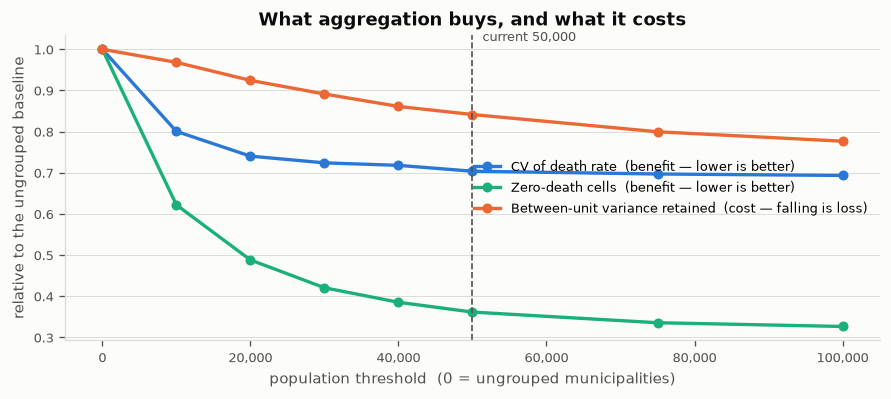

In [9]:
fig, ax = plt.subplots(figsize=(7.5, 3.4))
# One axis: everything expressed as a share of its own baseline value, so
# benefit and cost are directly comparable.
ax.plot(cv.index, cv/cv.iloc[0], color=BLUE, marker="o", markersize=5,
        label="CV of death rate  (benefit — lower is better)")
ax.plot(zero.index, zero/zero.iloc[0], color=AQUA, marker="o", markersize=5,
        label="Zero-death cells  (benefit — lower is better)")
ax.plot(v_obs.index, v_obs/v_obs.iloc[0], color=ORANGE, marker="o", markersize=5,
        label="Between-unit variance retained  (cost — falling is loss)")
ax.axvline(50_000, color=INK2, linestyle="--", linewidth=1)
ax.annotate("current 50,000", (50_000, 1.02), fontsize=8, color=INK2,
            textcoords="offset points", xytext=(6,0))
ax.set_xlabel("population threshold  (0 = ungrouped municipalities)")
ax.set_ylabel("relative to the ungrouped baseline")
ax.set_title("What aggregation buys, and what it costs")
ax.xaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.grid(axis="y"); ax.set_axisbelow(True); ax.legend(loc="center right")
plt.tight_layout(); plt.show()

**Section 2.4's stated criterion cannot have produced 50,000.** The CV falls monotonically all
the way to 100,000, so "minimise the CV" selects the *largest* threshold in the sweep. And the
benefit saturates early — 65% of the total available CV reduction lands by 10,000, 85% by
20,000, 90% by 30,000 — while the cost keeps rising close to linearly with no saturation.

A second finding from the same sweep: over an 11-year window, Poisson sampling noise is only
~3% of between-municipality variance **even ungrouped**. The noise problem is a *single-year*
problem, which changes how much aggregation the analysis actually needs.

The threshold is **left at 50,000** — where to sit on this trade-off is a statistical decision,
not a code one. `ch2_010` already writes a 30,000 grouping alongside it.

### 2.4 What the units look like now

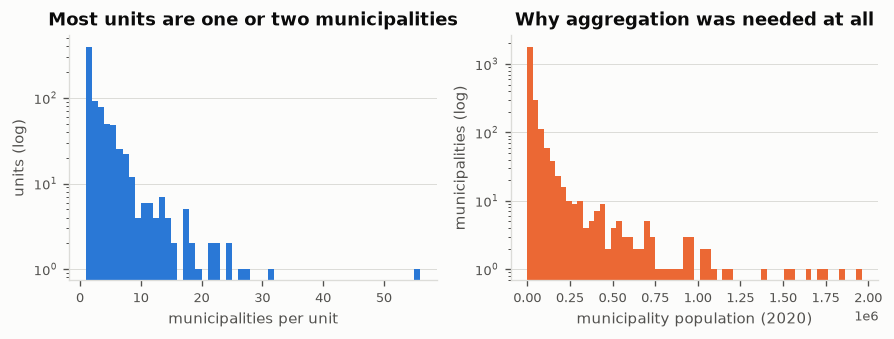

2,457 municipalities -> 777 units
median municipality 13,709  ->  median unit 90,110
smallest unit 50,055  (threshold 50,000)


In [10]:
per_unit = muni.groupby("group_id").size()
fig, axes = plt.subplots(1, 2, figsize=(7.5, 2.9))
axes[0].hist(per_unit, bins=range(1, per_unit.max()+2), color=BLUE)
axes[0].set_yscale("log")
axes[0].set_xlabel("municipalities per unit"); axes[0].set_ylabel("units (log)")
axes[0].set_title("Most units are one or two municipalities")
axes[1].hist(muni.total_pop, bins=60, color=ORANGE)
axes[1].set_yscale("log")
axes[1].set_xlabel("municipality population (2020)"); axes[1].set_ylabel("municipalities (log)")
axes[1].set_title("Why aggregation was needed at all")
for ax in axes: ax.grid(axis="y"); ax.set_axisbelow(True)
plt.tight_layout(); plt.show()

print(f"{len(muni):,} municipalities -> {len(units):,} units")
print(f"median municipality {muni.total_pop.median():,.0f}  ->  median unit {units.total_pop.median():,.0f}")
print(f"smallest unit {units.total_pop.min():,.0f}  (threshold 50,000)")